# Clustering and ML
This final notebook will apply an unsupervised K-Means clustering algorithm to segment Italian municipalities, build a Regression model to predict accidents, and export the final dataset for the Power BI dashboard storytelling.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df_raw = pd.read_csv("../data/2_final.csv")

print("Dataset loaded.")
df_raw.head()

Dataset loaded.


,REF_AREA,TIME_PERIOD,ACCIDENTS,DEATHS,INJURIES,NAME,PROVINCE,IS_PROVINCE_CAPITAL,IS_REGION_CAPITAL,AREA,POPULATION,ACCIDENTS_PER_1000_INH,DEATHS_PER_1000_INH,INJURIES_PER_1000_INH,ACCIDENTS_PER_KMQ,DEATHS_PER_KMQ,INJURIES_PER_KMQ,SEVERITY_INDEX
0,1001,2024,0,0,0,Agliè,TO,False,False,13.1463,2585,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1001,2024,0,0,0,Agliè,TO,False,False,13.1463,2585,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1001,2024,0,0,0,Agliè,TO,False,False,13.1463,2585,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1001,2024,0,0,0,Agliè,TO,False,False,13.1463,2585,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1001,2024,0,0,0,Agliè,TO,False,False,13.1463,2585,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## STEP 1. K-Means Clustering
We will apply an unsupervised K-Means clustering algorithm to segment Italian municipalities into distinct risk profiles, taking into account both the scale of a city and its accident density.

The dataset will be filtered two ways:
- only data from 2024 onwards, since the poopulation data we have refers to 2024; and
- only municipalities with a population of at least 2.000, in order to avoid distorted accident rates due to small denominators.

In [11]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# Filter the last three years and only municipalities with at least 2.000 inhabitants
df = df_raw[(df_raw["TIME_PERIOD"] == 2024) & (df_raw["POPULATION"] >= 2000)].copy()

# Select features for clustering
cluster_features = ["ACCIDENTS_PER_1000_INH", "ACCIDENTS_PER_KMQ"]
df_cluster = df[["NAME", "PROVINCE", "POPULATION"] + cluster_features].dropna().copy()

# Scale the features
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df_cluster[cluster_features])

# Add scaled features to dataframe
df_scaled = pd.DataFrame(scaled_features, columns=cluster_features)
df_scaled["NAME"] = df_cluster["NAME"].values
df_scaled["PROVINCE"] = df_cluster["PROVINCE"].values
df_scaled["POPULATION"] = df_cluster["POPULATION"].values

# Check
df_scaled.head()

,ACCIDENTS_PER_1000_INH,ACCIDENTS_PER_KMQ,NAME,PROVINCE,POPULATION
0,0.0,0.0,Agliè,TO,2585
1,0.0,0.0,Agliè,TO,2585
2,0.0,0.0,Agliè,TO,2585
3,0.0,0.0,Agliè,TO,2585
4,0.0,0.0,Agliè,TO,2585


We can now visualize a plot of the normalized features using the pairplot function to check if we can visually spot clusters.

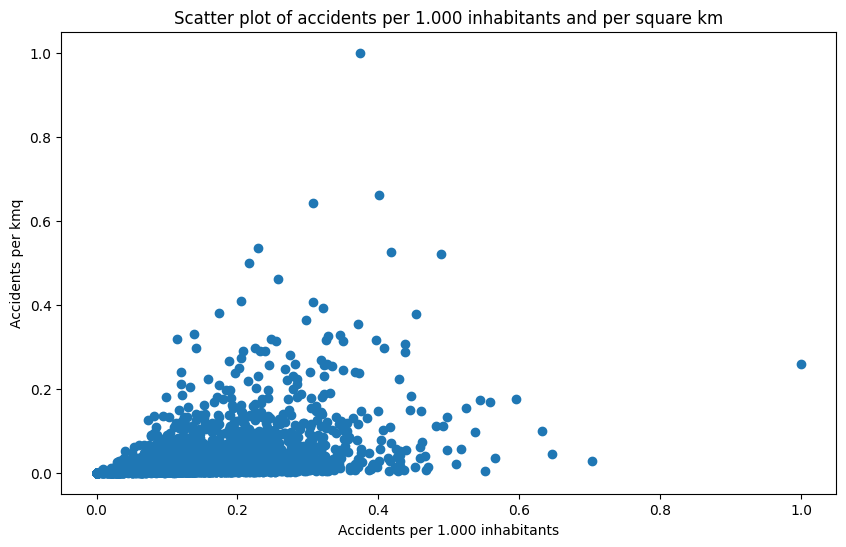

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(
    df_scaled["ACCIDENTS_PER_1000_INH"],
    df_scaled["ACCIDENTS_PER_KMQ"]
)

plt.title("Scatter plot of accidents per 1.000 inhabitants and per square km")
plt.xlabel("Accidents per 1.000 inhabitants")
plt.ylabel("Accidents per kmq")
plt.show()